### Import Libraries

In [1]:
# for manipulations
import numpy as np
import pandas as pd

In [2]:
# for data visualizations
import matplotlib.pyplot as plt
plt.rcParams['axes.autolimit_mode'] = 'round_numbers'
plt.style.use('fivethirtyeight')

In [3]:
# lets import the warnings library so that we can avoid warnings
import warnings
warnings.filterwarnings('ignore')

In [4]:
# Custom Function
from custom_function import *

In [5]:
# For Normalization
from sklearn.preprocessing import MinMaxScaler

### Loading

#### 1. Food Price

In [6]:
food_price = get_dataset('\\Datasets\\wfp_food_prices_mmr(Cleaned).csv')
food_price.drop(['latitude', 'longitude'],  axis='columns', inplace=True)
food_price.head()

,date,region,city,market,category,commodity,Exact Commodity,Quality,unit,priceflag,pricetype,currency,price,usdprice
0,1/15/2008,Kachin,Myitkyina,Wai Maw,cereals and tubers,Rice (low quality),Rice,low quality,KG,actual,Retail,MMK,400.00,0.2247
1,1/15/2008,Kachin,Myitkyina,Wai Maw,"meat, fish and eggs",Meat (chicken),chicken,NaN,KG,actual,Retail,MMK,3636.36,2.0429
2,1/15/2008,Kachin,Myitkyina,Wai Maw,"meat, fish and eggs",Meat (pork),pork,NaN,KG,actual,Retail,MMK,3636.36,2.0429
3,1/15/2008,Kachin,Myitkyina,Wai Maw,miscellaneous food,Salt,Salt,NaN,KG,actual,Retail,MMK,242.42,0.1362
4,1/15/2008,Kachin,Myitkyina,Wai Maw,vegetables and fruits,Onions,Onions,NaN,KG,actual,Retail,MMK,969.70,0.5448


In [7]:
food_price = food_price[['date', 'price']]
food_price['date'] = pd.to_datetime(food_price['date'])
food_price.columns = ['date', 'food_price']
food_price = food_price.set_index('date')
food_price = food_price.resample('AS-JAN').mean()
food_price.head()

,food_price
date,
2008-01-01,1002.766567
2009-01-01,805.337847
2010-01-01,900.166229
2011-01-01,972.709289
2012-01-01,832.871728


#### 2. Export Volume Dataset

In [8]:
temp_exp_vol = get_dataset('\\Datasets\\export_volume.csv')
temp_exp_vol.head()

,Country Name,Country Code,Indicator Name,Indicator Code,1960,1961,1962,1963,1964,1965,...,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020
0,Aruba,ABW,Export volume index (2000 = 100),TX.QTY.MRCH.XD.WD,NaN,NaN,NaN,NaN,NaN,NaN,...,62.327332,16.363516,3.390359,3.321520,5.187219,4.331915,1.896794,2.615290,1.769169,1.347102
1,Africa Eastern and Southern,AFE,Export volume index (2000 = 100),TX.QTY.MRCH.XD.WD,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,Afghanistan,AFG,Export volume index (2000 = 100),TX.QTY.MRCH.XD.WD,NaN,NaN,NaN,NaN,NaN,NaN,...,99.852413,125.517719,156.260916,176.226143,185.581555,190.967269,212.967729,248.447247,241.258274,198.221046
3,Africa Western and Central,AFW,Export volume index (2000 = 100),TX.QTY.MRCH.XD.WD,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,Angola,AGO,Export volume index (2000 = 100),TX.QTY.MRCH.XD.WD,NaN,NaN,NaN,NaN,NaN,NaN,...,228.389886,238.365558,236.629482,218.790884,229.216913,226.568225,221.535993,199.989747,188.029230,176.611064


In [9]:
temp_exp_vol = temp_exp_vol[temp_exp_vol['Country Code'] == 'MMR']
temp_exp_vol

,Country Name,Country Code,Indicator Name,Indicator Code,1960,1961,1962,1963,1964,1965,...,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020
160,Myanmar,MMR,Export volume index (2000 = 100),TX.QTY.MRCH.XD.WD,NaN,NaN,NaN,NaN,NaN,NaN,...,261.780994,246.79945,321.790067,341.234863,412.758483,463.789723,497.18952,556.211178,662.365798,645.299705


In [10]:
date = temp_exp_vol.columns
date = date[4:]
date

Index(['1960', '1961', '1962', '1963', '1964', '1965', '1966', '1967', '1968',
       '1969', '1970', '1971', '1972', '1973', '1974', '1975', '1976', '1977',
       '1978', '1979', '1980', '1981', '1982', '1983', '1984', '1985', '1986',
       '1987', '1988', '1989', '1990', '1991', '1992', '1993', '1994', '1995',
       '1996', '1997', '1998', '1999', '2000', '2001', '2002', '2003', '2004',
       '2005', '2006', '2007', '2008', '2009', '2010', '2011', '2012', '2013',
       '2014', '2015', '2016', '2017', '2018', '2019', '2020'],
      dtype='object')

In [11]:
date.shape

(61,)

In [12]:
export_volume = temp_exp_vol.copy()
export_volume = export_volume[date]
export_volume = export_volume.values
export_volume

array([[         nan,          nan,          nan,          nan,
                 nan,          nan,          nan,          nan,
                 nan,          nan,          nan,          nan,
                 nan,          nan,          nan,          nan,
                 nan,          nan,          nan,          nan,
                 nan,  20.65120826,  22.86825406,  22.74954218,
         18.08670725,  13.37564693,  15.35511517,  14.13514646,
          8.75547142,   9.6283485 ,  14.66173879,  20.25708611,
         31.67082677,  37.47708675,  38.40162791,  34.8311762 ,
         32.24566454,  41.51021412,  55.47688223,  63.32098162,
        100.        , 144.4960615 , 199.7314949 , 145.296133  ,
        128.9312483 , 170.8154023 , 173.7995612 , 227.9945376 ,
        197.618609  , 224.3447987 , 288.0412351 , 261.7809937 ,
        246.79945   , 321.7900675 , 341.2348626 , 412.7584827 ,
        463.7897233 , 497.1895204 , 556.2111779 , 662.3657977 ,
        645.2997048 ]])

In [13]:
date = pd.to_datetime(date, format='%Y')

In [14]:
export_volume = export_volume[0]
export_volume.shape

(61,)

In [15]:
exp_vol = pd.DataFrame()
exp_vol['export_volume'] = export_volume * 20
exp_vol

,export_volume
0,NaN
1,NaN
2,NaN
3,NaN
4,NaN
...,...
56,9275.794466
57,9943.790408
58,11124.223558
59,13247.315954


In [16]:
exp_vol['date']=date
exp_vol = exp_vol.set_index('date')
exp_vol.columns=['export_volume']
exp_vol.head()

,export_volume
date,
1960-01-01,NaN
1961-01-01,NaN
1962-01-01,NaN
1963-01-01,NaN
1964-01-01,NaN


In [17]:
exp_vol.dropna(inplace=True)
exp_vol.head()

,export_volume
date,
1981-01-01,413.024165
1982-01-01,457.365081
1983-01-01,454.990844
1984-01-01,361.734145
1985-01-01,267.512939


### Merge export_volume and food_price

In [18]:
food_export = food_price.join(exp_vol, how='inner')
food_export

,food_price,export_volume
date,,
2008-01-01,1002.766567,3952.372180
2009-01-01,805.337847,4486.895974
2010-01-01,900.166229,5760.824702
2011-01-01,972.709289,5235.619874
2012-01-01,832.871728,4935.989000
2013-01-01,914.454042,6435.801350
2014-01-01,1634.163191,6824.697252
2015-01-01,1885.676491,8255.169654
2016-01-01,2105.188314,9275.794466


### Correlation

In [19]:
correlation=food_export['food_price'].corr(food_export['export_volume'])
correlation

0.7397203050193645

### Make scatter plot

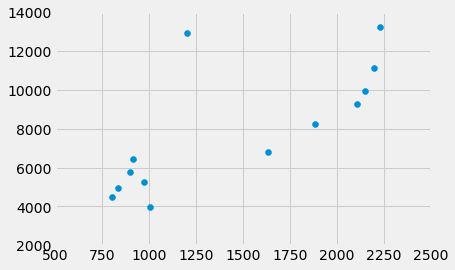

In [20]:
plt.scatter(food_export['food_price'],food_export['export_volume'])
plt.show()

### Normalization

In [21]:
date = food_export.index

In [22]:
scaler = MinMaxScaler()

In [23]:
food_export = scaler.fit_transform(food_export)
food_export = pd.DataFrame(food_export)
food_export['date'] = date
food_export.set_index('date', inplace=True)
food_export.columns = ['food_price', 'export_volume']
food_export.head()

,food_price,export_volume
date,,
2008-01-01,0.138512,0.000000
2009-01-01,0.000000,0.057507
2010-01-01,0.066530,0.194563
2011-01-01,0.117424,0.138059
2012-01-01,0.019317,0.105823


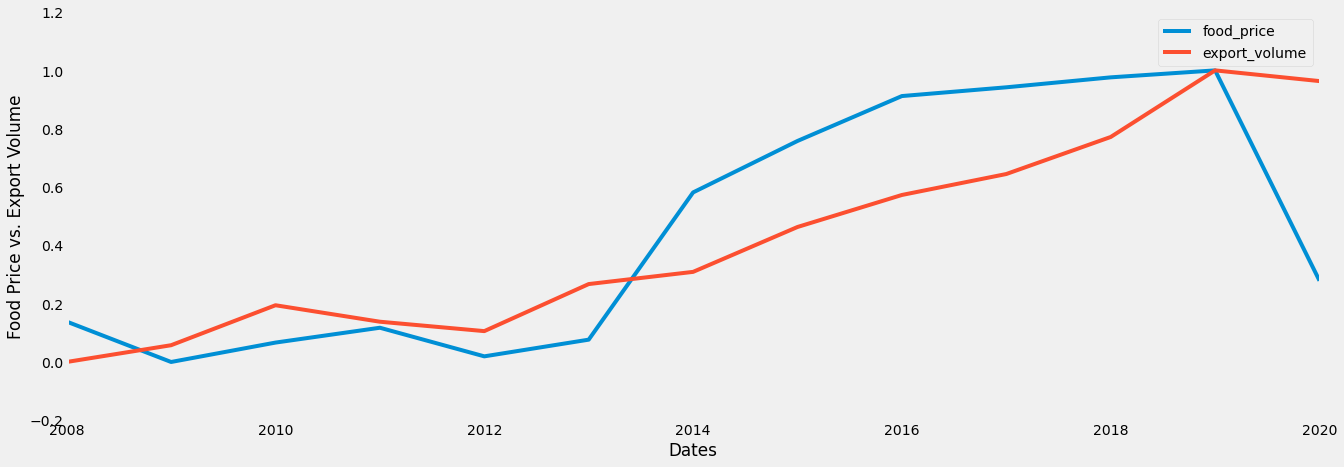

In [24]:
line_ax = food_export.plot(kind='line', figsize=(20, 7))
line_ax.set_ylabel('Food Price vs. Export Volume')
line_ax.set_xlabel('Dates')
line_ax.grid()

<span style="color:red">There is positive relation between Food Price and Export Volume</span>